Original Shape: (300, 2)

Number of Clusters: 2
Noise Points: 2
Cluster Labels: {np.int64(0), np.int64(1), np.int64(-1)}


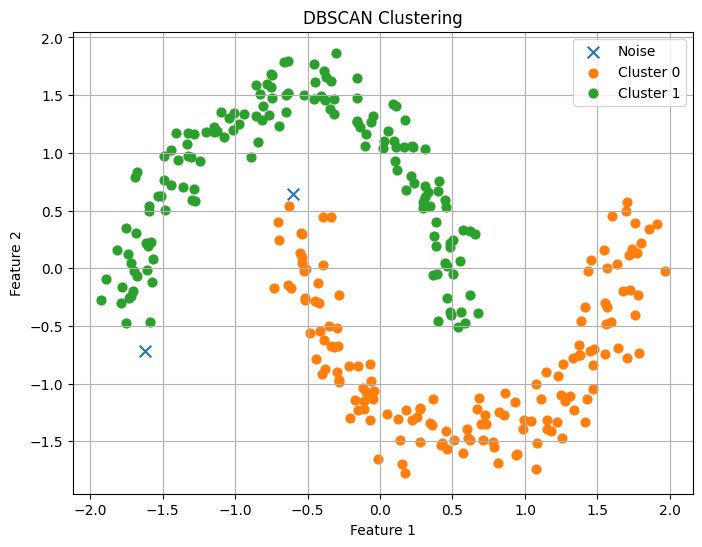

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# Generate dataset
X, y_true = make_moons(
    n_samples=300,
    noise=0.08,
    random_state=42
)

print("Original Shape:", X.shape)

# Scale data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply DBSCAN
dbscan = DBSCAN(
    eps=0.25,
    min_samples=5
)

labels = dbscan.fit_predict(X_scaled)

# Count clusters and noise
unique_labels = set(labels)

n_clusters = len(unique_labels - {-1})
n_noise = np.sum(labels == -1)

print("\nNumber of Clusters:", n_clusters)
print("Noise Points:", n_noise)
print("Cluster Labels:", unique_labels)

# Visualize clusters
plt.figure(figsize=(8, 6))

for label in sorted(unique_labels):
    mask = labels == label

    if label == -1:
        plt.scatter(
            X_scaled[mask, 0],
            X_scaled[mask, 1],
            label="Noise",
            marker="x",
            s=70
        )
    else:
        plt.scatter(
            X_scaled[mask, 0],
            X_scaled[mask, 1],
            label=f"Cluster {label}",
            s=40
        )

plt.title("DBSCAN Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()